[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C2_NB03_qif_network.ipynb)

# Day 1 · Chapter 2 · Notebook 03 — A network of QIF neurons

**Goal.** Connect thousands of QIF neurons and look at what the *population* does: asynchronous
low activity, transitions to high activity, damped collective oscillations, bistability and bursting.

The advantage of the simple neurons of NB02 is that we can now afford **10 000 neurons** on a laptop,
something that would be slow with Hodgkin–Huxley and impossible with detailed morphologies.

This notebook reproduces the *network* half of Fig. 2 of Montbrió, Pazó & Roxin (2015).
In Chapter 3 (NB05) we will show that this whole network is described *exactly* by two equations.

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import neurons, networks

## 1. The model

$N$ QIF neurons (NB02), each with its own excitability $\eta_j$, all receiving the same synaptic input and
the same external input:

$$
\frac{dv_j}{dt} = v_j^2 + \eta_j + J\,s(t) + I(t), \qquad j=1,\dots,N
$$

* $\eta_j$: **heterogeneity**. Neurons are not identical: some are close to firing, some far from it.
  The $\eta_j$ follow a **Lorentzian** (Cauchy) distribution centred at $\bar\eta$ with half-width $\Delta$:
  $\;g(\eta)=\frac{\Delta/\pi}{(\eta-\bar\eta)^2+\Delta^2}$.
* $s(t)$: the **population firing rate** (spikes per neuron per unit time, averaged over a short window).
  Every spike of every neuron excites all the others.
* $J$: synaptic strength ($J>0$: excitatory).
* $I(t)$: external input, identical for all neurons.
* Spike and reset as in NB02, with a higher cutoff: $v=+1000 \to -1000$ (the exact QIF goes to $\pm\infty$;
  the higher the cutoff, the closer the network is to the exact theory of Chapter 3).

**Connectivity: all-to-all.** Every neuron is connected to every other with the same weight $J/N$:
the connectivity matrix is full and uniform. This is the simplest possible network, and the one for which
the exact mean field of Chapter 3 holds.

Parameters (as in MPR 2015, Fig. 2): $\bar\eta=-5$, $\Delta=1$, $J=15$, $N=10^4$.
Time is in units of the membrane time constant ($\tau_m\approx 10$ ms).

fraction of neurons that would fire on their own (eta > 0): 0.063


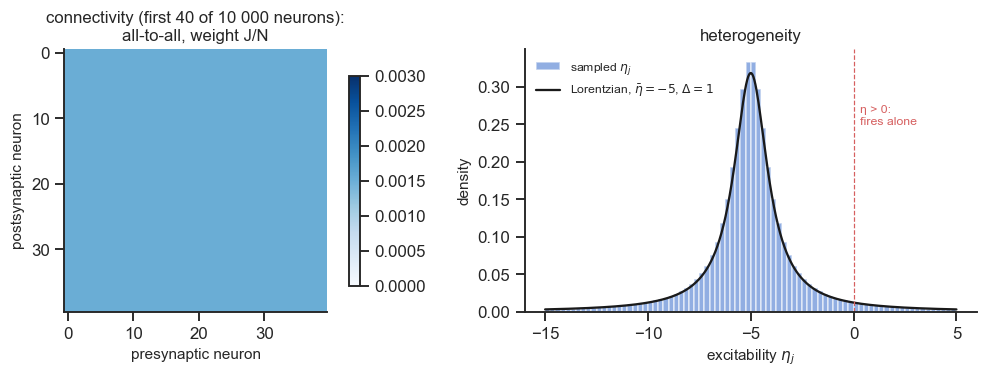

In [2]:
N_show = 40
eta = networks.lorentzian_etas(10000, eta_bar=-5.0, delta=1.0)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
W = np.full((N_show, N_show), 15.0 / 10000)
im = ax[0].imshow(W, cmap="Blues", vmin=0, vmax=2 * 15.0 / 10000)
ax[0].set(title=f"connectivity (first {N_show} of 10 000 neurons):\nall-to-all, weight J/N", xlabel="presynaptic neuron", ylabel="postsynaptic neuron")
plt.colorbar(im, ax=ax[0], shrink=0.8)
bins = np.linspace(-15, 5, 81)
ax[1].hist(eta, bins=bins, density=True, color="C0", alpha=0.6, label=r"sampled $\eta_j$")
x = np.linspace(-15, 5, 400)
ax[1].plot(x, (1.0 / np.pi) / ((x + 5.0) ** 2 + 1.0), "k", label=r"Lorentzian, $\bar\eta=-5$, $\Delta=1$")
ax[1].axvline(0, c="C3", ls="--", lw=0.8); ax[1].text(0.3, 0.25, "η > 0:\nfires alone", color="C3", fontsize=8)
ax[1].set(xlabel=r"excitability $\eta_j$", ylabel="density", title="heterogeneity")
ax[1].legend(fontsize=8)
plt.tight_layout()
print(f"fraction of neurons that would fire on their own (eta > 0): {np.mean(eta > 0):.3f}")

Most neurons are below threshold ($\eta_j<0$, excitable) and only ~6% would fire on their own.
The Lorentzian has heavy tails: a few neurons are very excitable, a few are very silent.

## 2. Without coupling ($J=0$): just a collection of neurons

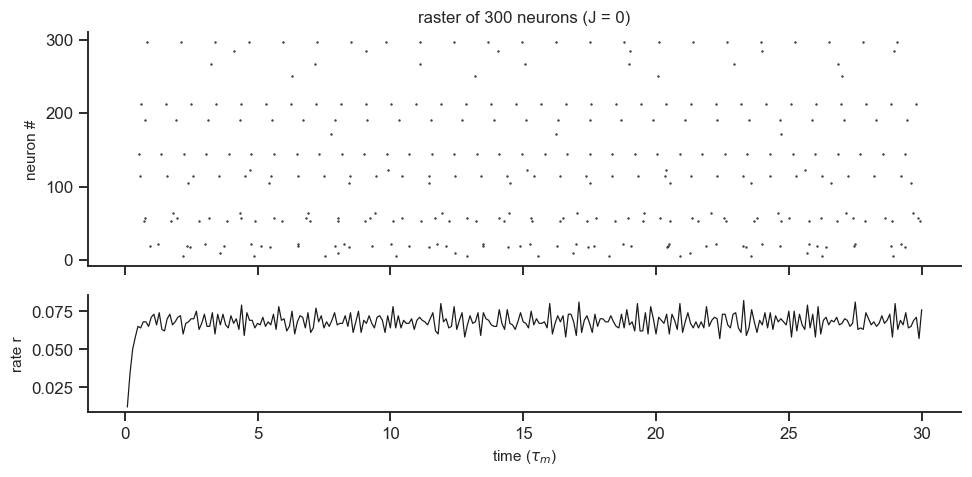

In [3]:
dt = 1e-4
t = np.arange(0, 30, dt)
tb, r, v, st, si = networks.qif_network(np.zeros(t.size), N=10000, J=0.0, dt=dt, n_rec=300, seed=0, bin_size=0.1)

fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
ax[0].plot(st, si, ".k", ms=1)
ax[0].set(ylabel="neuron #", title="raster of 300 neurons (J = 0)")
ax[1].plot(tb, r, "k", lw=0.8)
ax[1].set(xlabel="time ($\\tau_m$)", ylabel="rate r")
plt.tight_layout()

(The rate is averaged in bins of 0.1 time units; in the other plots we use 0.02–0.05.)
Each active neuron fires regularly at its own rate $\sqrt{\eta_j}/\pi$ (NB02). Neurons are not
synchronised, so the population rate $r(t)$ is flat: the network is in an **asynchronous** state.

## 3. With coupling ($J=15$): a step of input

We start the network in its low-activity state and apply a step $I=3$ between $t=0$ and $t=30$.

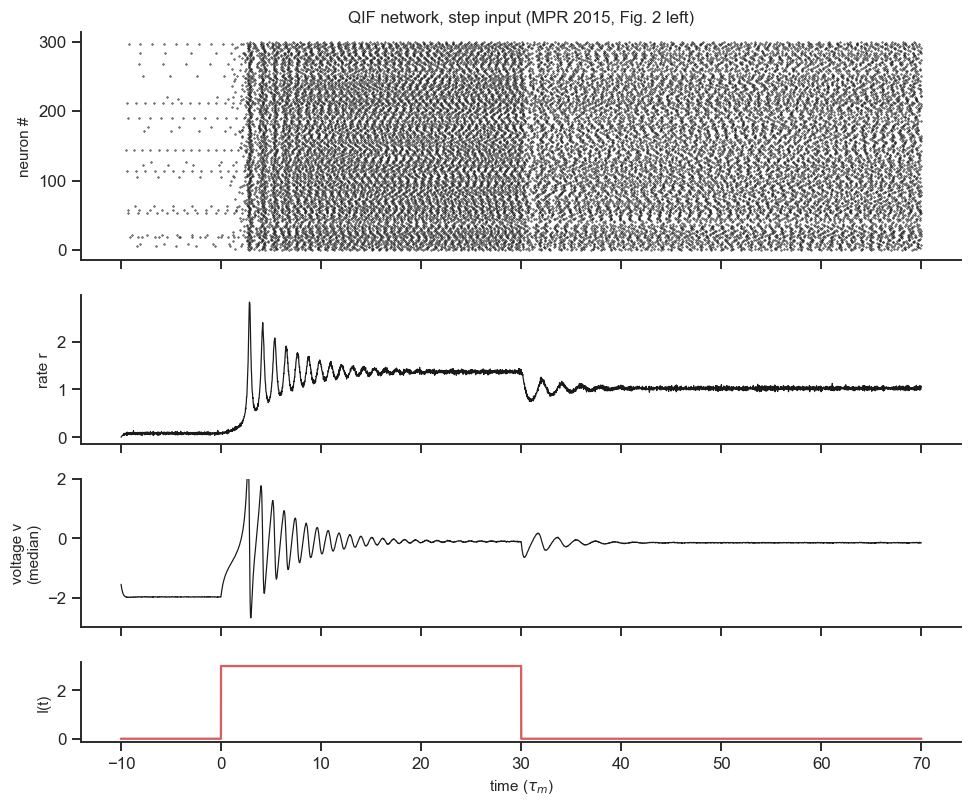

In [4]:
T0, T = -10.0, 70.0
t = np.arange(T0, T, dt)
I_step = np.where((t >= 0) & (t < 30), 3.0, 0.0)
tb, r, v, st, si = networks.qif_network(I_step, N=10000, J=15.0, dt=dt, n_rec=300, seed=0, bin_size=0.02)
tb = tb + T0; st = st + T0

def plot_network(tb, r, v, st, si, t, I, title):
    fig, ax = plt.subplots(4, 1, figsize=(9, 7.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1.3, 1.3, 0.7]))
    ax[0].plot(st, si, ".k", ms=0.8); ax[0].set(ylabel="neuron #", title=title)
    ax[1].plot(tb, r, "k", lw=0.8); ax[1].set(ylabel="rate r")
    ax[2].plot(tb, v, "k", lw=0.8); ax[2].set(ylabel="voltage v\n(median)", ylim=(-3, 2))
    ax[3].plot(t, I, "C3"); ax[3].set(xlabel="time ($\\tau_m$)", ylabel="I(t)")
    plt.tight_layout()

plot_network(tb, r, v, st, si, t, I_step, "QIF network, step input (MPR 2015, Fig. 2 left)")

Three things happen that no single neuron does:

1. **Collective oscillations.** At the onset of the step many neurons fire *together*, then together
   again, and the population rate oscillates with decaying amplitude before settling to a high value.
   No single neuron oscillates like this: it is a property of the population.
2. **High-activity state.** During the step the network fires at a much higher rate.
3. **Memory (bistability).** When the input is removed at $t=30$ the network does **not** go back to low
   activity. The same network, with the same input ($I=0$), can be in two states, and which one depends on
   its history. This is *hysteresis*, as in the HH neuron of NB01 — but here it is a property of the
   population, created by the recurrent excitation $J$.

## 4. A sinusoidal input: bursting

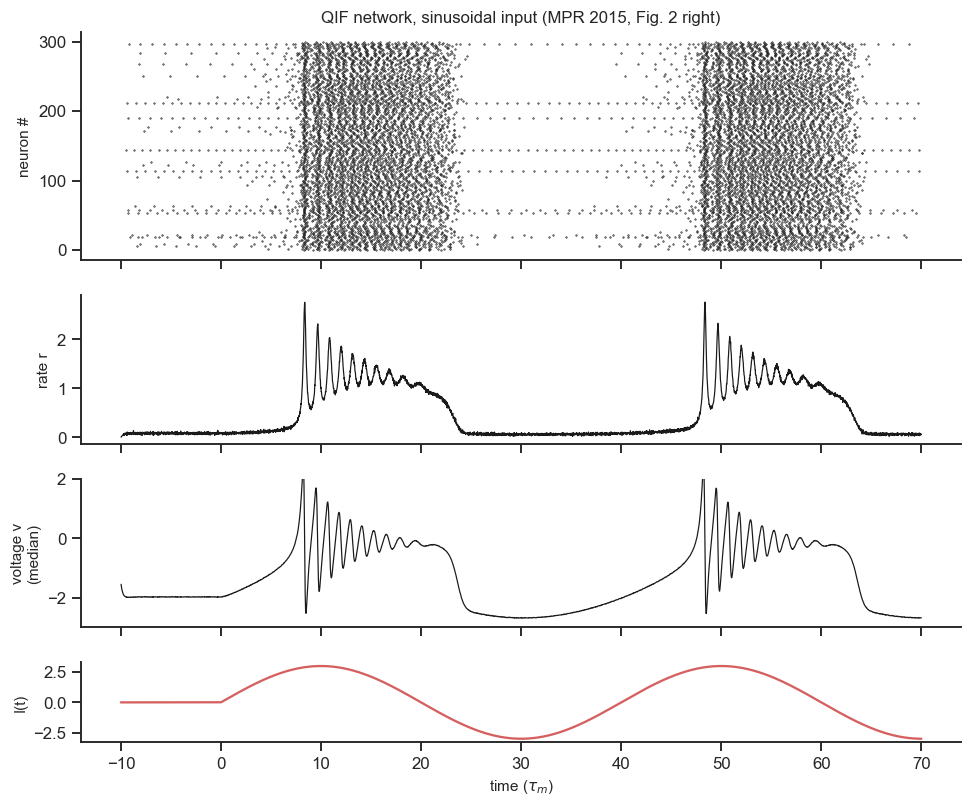

In [5]:
I_sin = 3.0 * np.sin(np.pi * t / 20.0) * (t >= 0)
tb, r, v, st, si = networks.qif_network(I_sin, N=10000, J=15.0, dt=dt, n_rec=300, seed=0, bin_size=0.02)
plot_network(tb + T0, r, v, st + T0, si, t, I_sin, "QIF network, sinusoidal input (MPR 2015, Fig. 2 right)")

A slow input that goes up and down makes the network switch between the low and the high state: it
fires in **bursts**. Each burst starts with fast collective oscillations. The switch up happens late
(when the input is already high) and the switch down happens late too (when the input is already low):
again hysteresis.

## 5. How many neurons do we need?

The population rate is an average over neurons, so it is noisy when $N$ is small.

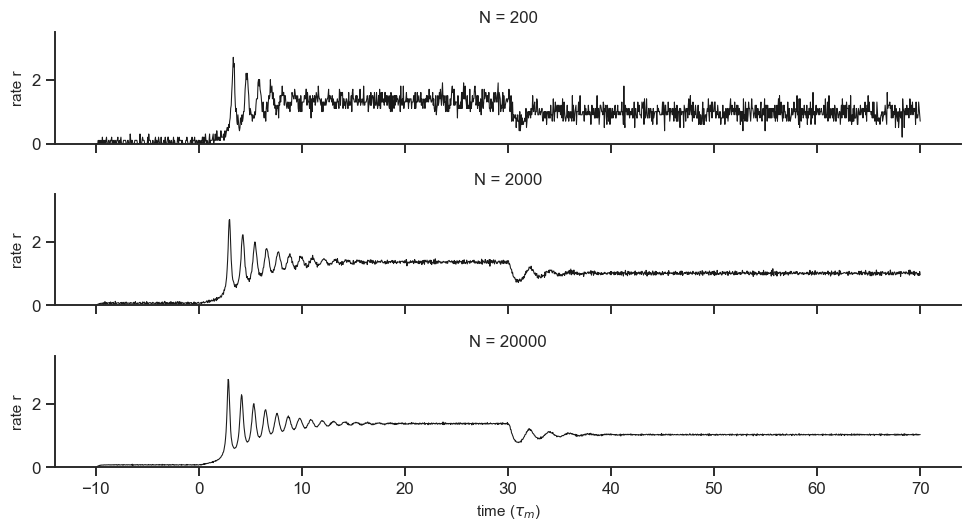

In [6]:
dt2 = 5e-4
t2 = np.arange(T0, T, dt2)
I2 = np.where((t2 >= 0) & (t2 < 30), 3.0, 0.0)
fig, ax = plt.subplots(3, 1, figsize=(9, 5), sharex=True, sharey=True)
for a_, N in zip(ax, [200, 2000, 20000]):
    tb, r, v, st, si = networks.qif_network(I2, N=N, J=15.0, dt=dt2, seed=1, bin_size=0.05)
    a_.plot(tb + T0, r, "k", lw=0.7); a_.set(ylabel="rate r", title=f"N = {N}", ylim=(0, 3.5))
ax[-1].set_xlabel("time ($\\tau_m$)")
plt.tight_layout()

Fluctuations of the population rate shrink as $N$ grows (roughly as $1/\sqrt N$), and a smooth,
deterministic curve emerges. **Question for Chapter 3:** if the population rate is a smooth curve for large
$N$, can we write an equation directly for it, instead of simulating every neuron?

### Explore: the network as a function of its parameters

The network here has $N=5000$ neurons and a coarser time step (0.5 s per run). A step of input of
amplitude $I_0$ is applied between $t=0$ and $t=30$.

* Set $J=0$: are there collective oscillations? Is there memory after the step?
* With $J=15$, make the step smaller. Is there a minimum step that switches the network to high activity?
* Increase the heterogeneity $\Delta$. What happens to the oscillations and to the memory?
* Find values of $\bar\eta$ for which the network is in the high state even *before* the step.

In [8]:
@interact(J=slider(15.0, 0.0, 25.0, 0.5, "coupling J"),
          eta_bar=slider(-5.0, -10.0, 2.0, 0.25, "mean excitability eta_bar"),
          delta=slider(1.0, 0.1, 3.0, 0.1, "heterogeneity Delta"),
          I0=slider(3.0, -3.0, 6.0, 0.25, "step amplitude I0"))
def explore_network(J, eta_bar, delta, I0):
    dtx = 5e-4
    tx = np.arange(T0, T, dtx)
    Ix = np.where((tx >= 0) & (tx < 30), I0, 0.0)
    tb, r, v, st, si = networks.qif_network(Ix, N=5000, J=J, eta_bar=eta_bar, delta=delta, dt=dtx, n_rec=200, seed=0, bin_size=0.05)
    fig, ax = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1.3, 0.6]))
    ax[0].plot(st + T0, si, ".k", ms=0.8); ax[0].set(ylabel="neuron #", title=f"J={J}, eta_bar={eta_bar}, Delta={delta}, I0={I0}")
    ax[1].plot(tb + T0, r, "k", lw=0.8); ax[1].set(ylabel="rate r")
    ax[2].plot(tx, Ix, "C3"); ax[2].set(xlabel="time ($\\tau_m$)", ylabel="I(t)")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=15.0, continuous_update=False, description='coupling J', layout=Layout…

## 6. Take-home

* Simple units make large networks affordable: 10 000 neurons in a few seconds.
* The population shows behaviours that no single neuron has: collective oscillations, a high-activity
  state sustained by recurrent excitation, bistability and memory, bursting under slow input.
* For large $N$ the population rate becomes a smooth curve. Next: an exact equation for it (NB05).

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. Run the step protocol with $J=0$ and $I_0=3$. Compare the firing rate during the step with the average of $\sqrt{\eta_j+I_0}/\pi$ over the neurons with $\eta_j+I_0>0$.
2. Find (with the sliders, then with a loop) the smallest step $I_0$ that switches the network from low to high activity for $J=15$, $\bar\eta=-5$, $\Delta=1$.
3. Apply a *negative* step after the network is in the high state. How strong must it be to switch the network back down? Draw the hysteresis loop: final state vs input.
4. Make the period of the sinusoidal input 10 times shorter ($I(t)=3\sin(\pi t/2)$). Does the network still follow the input?

### References
* Montbrió E, Pazó D, Roxin A (2015). Macroscopic description for networks of spiking neurons. *Phys Rev X* 5:021028.
* Brunel N (2000). Dynamics of sparsely connected networks of excitatory and inhibitory spiking neurons. *J Comput Neurosci* 8:183–208.
* Gerstner W et al. (2014). *Neuronal Dynamics*, ch. 12–13 (free online).